# Notebook 01: Multi-Source Data Ingestion & Web Crawling Pipeline (Module Ingestion)
> **Mục tiêu đồ án TradeToiChet**:
> 1. Thu thập dữ liệu Giá OHLCV 30 mã VN30 và chỉ số VN-Index (2019 - 2026).
> 2. Xây dựng dữ liệu Vĩ mô & Thị trường (Lãi suất tái cấp vốn SBV, Tỷ giá USD/VND, Biến động VN-Index).
> 3. Cào dữ liệu Tin tức doanh nghiệp từ CafeF bằng Web Scraper chống chặn IP (Anti-ban crawler).
> 4. Mô hình Học máy Chưng cất (Distilled Sentiment Model) chấm điểm cảm xúc tin tức tài chính tiếng Việt.
> 5. Kiểm tra schema, kiểu dữ liệu, missing values và tiêu chuẩn bàn giao dữ liệu thô (Data Contracts).

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Thiet lap project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DATA_RAW_DIR, SQLITE_DB_PATH, VN30_TICKERS
from src.ingestion.price_fetcher import sync_all_prices
from src.ingestion.macro_builder import build_macro_dataset
from src.ingestion.news_crawler import sync_all_news
from src.ingestion.sentiment import score_vietnamese_headline
from src.ingestion.db import get_connection

print('Moi truong san sang. Thu muc du lieu thuc te:', DATA_RAW_DIR)

Moi truong san sang. Thu muc du lieu thuc te: /home/kibito/Desktop/repos/TradeToiChet/data/raw


## 1. Dữ liệu Giá Lịch sử OHLCV (30 mã VN30 & Chỉ số VN-Index)
- **Nguồn**: API biểu đồ kỹ thuật Entrade/DNSE (`services.entrade.com.vn`).
- **Cơ chế**: Tải dữ liệu nến ngày từ 01/01/2019 đến 01/03/2026. Tự động lưu cache SQLite (`bảng prices`), nếu đã có dữ liệu thì nạp trực tiếp tức thì từ SQLite không tốn request mạng.
- **Xử lý missing / điền khuyết**: Kiểm tra null trên từng cột giá và khối lượng; chuẩn hóa timezone về naive UTC datetime; lọc trùng lặp `(date, ticker)`.

In [2]:
# 1. Chay sync du lieu gia (Hit cache SQLite tuc thi neu da nap san)
df_prices = sync_all_prices(output_dir=DATA_RAW_DIR, db_path=SQLITE_DB_PATH)

# 2. Kiem tra schema, kieu du lieu va missing values
print('--- THONG TIN SCHEMA & KIEU DU LIEU (PRICES) ---')
df_prices.info()

print('\n--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---')
print(df_prices.isnull().sum())

print(f'\nTong so ma co phieu: {df_prices["ticker"].nunique()} | Khoang thoi gian: {df_prices["date"].min().date()} den {df_prices["date"].max().date()}')
df_prices.head(5)

[01/31] Cache hit in SQLite for ACB (2019-01-02 -> 2026-11-19).
[02/31] Cache hit in SQLite for BCM (2019-01-02 -> 2026-11-19).
[03/31] Cache hit in SQLite for BID (2019-01-02 -> 2026-11-19).
[04/31] Cache hit in SQLite for BVH (2019-01-02 -> 2026-11-19).
[05/31] Cache hit in SQLite for CTG (2019-01-02 -> 2026-11-19).
[06/31] Cache hit in SQLite for FPT (2019-01-02 -> 2026-11-19).
[07/31] Cache hit in SQLite for GAS (2019-01-02 -> 2026-11-19).
[08/31] Cache hit in SQLite for GVR (2019-01-02 -> 2026-11-19).
[09/31] Cache hit in SQLite for HDB (2019-01-02 -> 2026-11-19).
[10/31] Cache hit in SQLite for HPG (2019-01-02 -> 2026-11-19).
[11/31] Cache hit in SQLite for MBB (2019-01-02 -> 2026-11-19).
[12/31] Cache hit in SQLite for MSN (2019-01-02 -> 2026-11-19).
[13/31] Cache hit in SQLite for MWG (2019-01-02 -> 2026-11-19).
[14/31] Cache hit in SQLite for PLX (2019-01-02 -> 2026-11-19).
[15/31] Incremental OHLCV fetch for POW (2019-01-01 -> 2019-01-14)...


[16/31] Cache hit in SQLite for SAB (2019-01-02 -> 2026-11-19).
[17/31] Cache hit in SQLite for SHB (2019-01-02 -> 2026-11-19).
[18/31] Incremental OHLCV fetch for SSB (2019-01-01 -> 2021-03-24)...


[19/31] Cache hit in SQLite for SSI (2019-01-02 -> 2026-11-19).
[20/31] Cache hit in SQLite for STB (2019-01-02 -> 2026-11-19).
[21/31] Cache hit in SQLite for TCB (2019-01-02 -> 2026-11-19).
[22/31] Cache hit in SQLite for TPB (2019-01-02 -> 2026-11-19).
[23/31] Cache hit in SQLite for VCB (2019-01-02 -> 2026-11-19).
[24/31] Cache hit in SQLite for VHM (2019-01-02 -> 2026-11-19).
[25/31] Cache hit in SQLite for VIB (2019-01-02 -> 2026-11-19).
[26/31] Cache hit in SQLite for VIC (2019-01-02 -> 2026-11-19).
[27/31] Cache hit in SQLite for VJC (2019-01-02 -> 2026-11-19).
[28/31] Cache hit in SQLite for VNM (2019-01-02 -> 2026-11-19).
[29/31] Cache hit in SQLite for VPB (2019-01-02 -> 2026-11-19).
[30/31] Cache hit in SQLite for VRE (2019-01-02 -> 2026-11-19).
[31/31] Cache hit in SQLite for VNINDEX (2019-01-02 -> 2026-11-19).


[OK] Saved 60,354 rows (31 tickers) to /home/kibito/Desktop/repos/TradeToiChet/data/raw/prices.parquet
--- THONG TIN SCHEMA & KIEU DU LIEU (PRICES) ---
<class 'pandas.DataFrame'>
RangeIndex: 60354 entries, 0 to 60353
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    60354 non-null  datetime64[us]
 1   ticker  60354 non-null  str           
 2   open    60354 non-null  float64       
 3   high    60354 non-null  float64       
 4   low     60354 non-null  float64       
 5   close   60354 non-null  float64       
 6   volume  60354 non-null  float64       
 7   sector  60354 non-null  str           
dtypes: datetime64[us](1), float64(5), str(2)
memory usage: 4.3 MB

--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---
date      0
ticker    0
open      0
high      0
low       0
close     0
volume    0
sector    0
dtype: int64

Tong so ma co phieu: 31 | Khoang thoi gian: 2019-01-02 den 2026-11-19


,date,ticker,open,high,low,close,volume,sector
0,2019-01-02,ACB,5.66,5.66,5.53,5.58,1103106.0,Banking
1,2019-01-03,ACB,5.02,5.57,5.02,5.38,1956382.0,Banking
2,2019-01-04,ACB,5.35,5.45,5.27,5.41,2771983.0,Banking
3,2019-01-07,ACB,5.53,5.53,5.45,5.49,1305819.0,Banking
4,2019-01-08,ACB,6.00,6.00,5.45,5.45,846226.0,Banking


## 2. Dữ liệu Vĩ mô & Thị trường (Macro Features)
- **Nguồn**:
  1. Suất sinh lời ngày và độ biến động 20 phiên tính từ chuỗi giá đóng cửa của chỉ số VN-Index (`vnindex_return_1d`, `vnindex_volatility_20d`).
  2. Lãi suất tái cấp vốn điều hành của Ngân hàng Nhà nước Việt Nam (`sbv_policy_rate`).
  3. Tỷ giá quy chuẩn USD/VND theo từng chu kỳ năm (`usd_vnd_rate`).
- **Xử lý missing / điền khuyết**: Phiên đầu tiên chưa có lợi nhuận ngày hôm trước được fill `0.0`. Độ biến động 20 phiên đầu tiên chưa đủ window 20 ngày được fill `0.0`.

In [3]:
# 1. Xay dung bang vi mo tu df_prices
df_macro = build_macro_dataset(df_prices=df_prices, output_dir=DATA_RAW_DIR, db_path=SQLITE_DB_PATH)

# 2. Kiem tra schema va mau du lieu
print('--- THONG TIN SCHEMA & KIEU DU LIEU (MACRO) ---')
df_macro.info()

print('\n--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---')
print(df_macro.isnull().sum())

df_macro.head(5)

[OK] Saved 1,934 rows of macro indicators to /home/kibito/Desktop/repos/TradeToiChet/data/raw/macro.parquet
--- THONG TIN SCHEMA & KIEU DU LIEU (MACRO) ---
<class 'pandas.DataFrame'>
RangeIndex: 1934 entries, 0 to 1933
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   date                    1934 non-null   datetime64[us]
 1   vnindex_close           1934 non-null   float64       
 2   vnindex_return_1d       1934 non-null   float64       
 3   vnindex_volatility_20d  1915 non-null   float64       
 4   usd_vnd_rate            1934 non-null   float64       
 5   sbv_policy_rate         1934 non-null   float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 90.8 KB

--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---
date                       0
vnindex_close              0
vnindex_return_1d          0
vnindex_volatility_20d    19
usd_vnd_rate               0
sbv_policy_rate

,date,vnindex_close,vnindex_return_1d,vnindex_volatility_20d,usd_vnd_rate,sbv_policy_rate
0,2019-01-02,891.75,0.000000,NaN,23194.0,6.25
1,2019-01-03,878.22,-0.015172,NaN,23194.0,6.25
2,2019-01-04,880.90,0.003052,NaN,23194.0,6.25
3,2019-01-07,889.64,0.009922,NaN,23194.0,6.25
4,2019-01-08,887.44,-0.002473,NaN,23194.0,6.25


## 3. Cào Tin tức Doanh nghiệp từ CafeF (Web Scraping & Anti-ban)
- **Nguồn**: Chuyên mục sự kiện và tin tức doanh nghiệp CafeF (`cafef.vn/du-lieu/Ajax/Events_RelatedNews_New.aspx`).
- **Cơ chế cào**:
  - `requests` kết hợp `BeautifulSoup4` bóc tách DOM HTML thẻ `span.timeTitle` và `a.docnhanhTitle`.
  - Chống chặn IP (Anti-ban): xoay vòng 6 User-Agent trình duyệt thật, độ trễ ngẫu nhiên jitter (0.3s - 0.7s), cơ chế retry exponential backoff.
  - Lưu trữ đệm vào SQLite bảng `raw_news` (`INSERT OR IGNORE`) chống cào trùng tin đã có.
- **Xử lý missing / điền khuyết**: Các tin tức thiếu ngày hoặc tiêu đề rỗng bị loại bỏ; chuẩn hóa định dạng ngày `DD/MM/YYYY` sang ISO `YYYY-MM-DD`.

In [4]:
# 1. Chay crawler dong bo tin tuc (neu da co trong SQLite se hit cache)
df_news = sync_all_news(output_dir=DATA_RAW_DIR, db_path=SQLITE_DB_PATH)

# 2. Kiem tra schema bang news_sentiment da tong hop
print('--- THONG TIN SCHEMA & KIEU DU LIEU (NEWS SENTIMENT) ---')
df_news.info()

print('\n--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---')
print(df_news.isnull().sum())

df_news.head(5)

[01/30] Syncing CafeF news for ACB (2019-01-01 -> 2026-11-20)...


    -> Inserted 0 new articles for ACB
[02/30] Syncing CafeF news for BCM (2019-01-01 -> 2026-11-20)...


    -> Inserted 0 new articles for BCM
[03/30] Syncing CafeF news for BID (2019-01-01 -> 2026-11-20)...


    -> Inserted 0 new articles for BID
[04/30] Syncing CafeF news for BVH (2019-01-01 -> 2026-11-20)...


    -> Inserted 0 new articles for BVH
[05/30] Syncing CafeF news for CTG (2019-01-01 -> 2026-11-20)...


    -> Inserted 0 new articles for CTG
[06/30] Syncing CafeF news for FPT (2019-01-01 -> 2026-11-20)...


... (23 outputs left out)

    -> Inserted 0 new articles for VPB
[30/30] Syncing CafeF news for VRE (2019-01-01 -> 2026-11-20)...


    -> Inserted 0 new articles for VRE


[STATS] Raw news articles by year: {2019: 3353, 2020: 4255, 2021: 3970, 2022: 3032, 2023: 3364, 2024: 3098, 2025: 3844, 2026: 3262}
[OK] Saved 18,249 daily ticker-news rows (from 28,178 articles) to /home/kibito/Desktop/repos/TradeToiChet/data/raw/news_sentiment.parquet
--- THONG TIN SCHEMA & KIEU DU LIEU (NEWS SENTIMENT) ---
<class 'pandas.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             18249 non-null  datetime64[us]
 1   ticker           18249 non-null  str           
 2   news_count       18249 non-null  int64         
 3   sentiment_score  18249 non-null  float64       
 4   sample_headline  18249 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(2)
memory usage: 2.4 MB

--- KIEM TRA GIA TRI THIEU (NULL / MISSING) ---
date               0
ticker             0
news_count         0
sentiment_score

,date,ticker,news_count,sentiment_score,sample_headline
0,2019-01-03,ACB,2,0.5871,ACB: Vợ ông Từ Tiến Phát - Phó Tổng Giám đốc đ...
1,2019-01-07,ACB,1,0.5055,Lợi nhuận ngân hàng chuẩn bị bùng nổ
2,2019-01-16,ACB,2,0.1287,ACB: Công bố thông tin quyết định của Tổng cục...
3,2019-01-21,ACB,1,0.0266,ACB: Thông báo về việc sửa đổi nội dung Giấy p...
4,2019-01-24,ACB,1,0.8333,Lộ diện TOP 10 lợi nhuận ngân hàng năm 2018


In [5]:
# 3. Kiem tra truc tiep cac mau bai bao tho da cao luu trong SQLite
with get_connection(SQLITE_DB_PATH) as conn:
    total_articles = pd.read_sql_query('SELECT count(*) as total FROM raw_news', conn)['total'].iloc[0]
    df_raw_samples = pd.read_sql_query(
        'SELECT ticker, pub_date, headline FROM raw_news ORDER BY pub_date DESC LIMIT 10',
        conn
    )
print(f'Tong so bai bao goc da cao va luu trong SQLite cache: {total_articles}')
df_raw_samples

Tong so bai bao goc da cao va luu trong SQLite cache: 28179


,ticker,pub_date,headline
0,FPT,2026-11-22,FPT bốc hơi 23.000 tỷ đồng vốn hóa sau một thá...
1,FPT,2026-11-20,FPT tăng giá 9% với 55 khách hàng Nhật Bản khi...
2,FPT,2026-11-20,Cổ phiếu
3,BID,2026-11-20,BID: Nghị quyết HĐQT phê duyệt một số nội dung...
4,BVH,2026-11-20,BVH: Công đoàn Tập đoàn Bảo Việt chưa bán cp
5,HDB,2026-11-20,HDB: Thông báo nhận được Quyết định của NHNN v...
6,HDB,2026-11-20,HDB: Thông báo về việc thay đổi địa điểm và tê...
7,HDB,2026-11-20,HDB: Nghị quyết HĐQT về việc lấy ý kiến cổ đôn...
8,MBB,2026-11-20,MBB: Công đoàn cơ sở MBB đã nhận chuyển nhượng...
9,TCB,2026-11-20,TCB: Thông báo phát hành cổ phiếu theo chương ...


## 4. Mô hình Học máy Chấm điểm Cảm xúc (Distilled Sentiment Model)
- **Cơ chế**: Huấn luyện pipeline `TfidfVectorizer(ngram_range=(1, 3)) + LogisticRegression(class_weight="balanced")` trên 2.526 tiêu đề thật được gán nhãn bởi LLM, đóng gói thành model `data/models/sentiment_tfidf.joblib`.
- **Điểm cảm xúc**: Tính theo chênh lệch xác suất `P(tích cực) - P(tiêu cực)` trong đoạn `[-1.0, 1.0]`.
- **Tốc độ**: < 0.1ms/câu, chạy hoàn toàn offline trên CPU.

In [6]:
# Thu nghiem truc tiep ham cham diem cam xuc
test_samples = [
    'Lợi nhuận quý 3 tăng trưởng kỷ lục 45%, vượt xa kế hoạch năm',
    'Hội đồng quản trị thông báo ngày đăng ký cuối cùng để trả cổ tức',
    'Doanh nghiệp thua lỗ nặng, cổ phiếu bị đưa vào diện đình chỉ giao dịch',
    'Khối ngoại mua ròng hàng trăm tỷ đồng cổ phiếu ngân hàng'
]

print('--- DEMO SUY LUAN DIEM CAM XUC TREN CPU (<0.1ms/cau) ---')
for text in test_samples:
    score = score_vietnamese_headline(text)
    label = 'TICH CUC' if score > 0.15 else ('TIEU CUC' if score < -0.15 else 'TRUNG LAP')
    print(f'[{score:+.4f}] ({label:<9}) : {text}')

--- DEMO SUY LUAN DIEM CAM XUC TREN CPU (<0.1ms/cau) ---
[+0.4346] (TICH CUC ) : Lợi nhuận quý 3 tăng trưởng kỷ lục 45%, vượt xa kế hoạch năm
[+0.2709] (TICH CUC ) : Hội đồng quản trị thông báo ngày đăng ký cuối cùng để trả cổ tức
[-0.6257] (TIEU CUC ) : Doanh nghiệp thua lỗ nặng, cổ phiếu bị đưa vào diện đình chỉ giao dịch
[+0.4057] (TICH CUC ) : Khối ngoại mua ròng hàng trăm tỷ đồng cổ phiếu ngân hàng


## 5. Trực quan hóa Dữ liệu & Kiểm định Tiêu chuẩn Bàn giao (DoD)

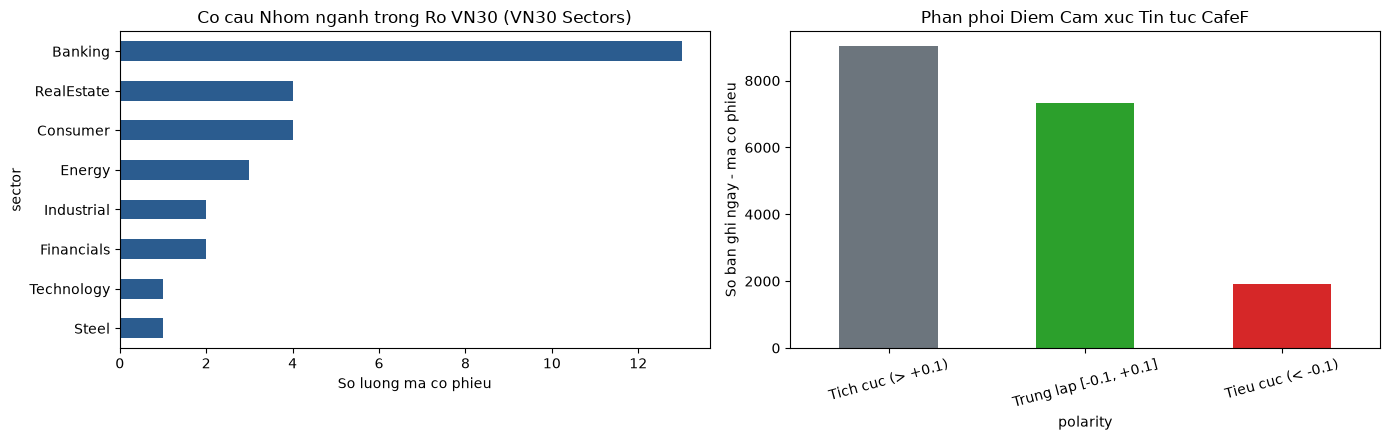

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Bieu do 1: Phan bo so luong phien giao dich theo nhom nganh
sector_counts = df_prices[df_prices['ticker'] != 'VNINDEX'].groupby('sector')['ticker'].nunique().sort_values()
sector_counts.plot(kind='barh', ax=axes[0], color='#2b5c8f')
axes[0].set_title('Co cau Nhom nganh trong Ro VN30 (VN30 Sectors)')
axes[0].set_xlabel('So luong ma co phieu')

# Bieu do 2: Phan phoi diem cam xuc tin tuc CafeF
df_news['polarity'] = df_news['sentiment_score'].apply(
    lambda s: 'Tich cuc (> +0.1)' if s > 0.1 else ('Tieu cuc (< -0.1)' if s < -0.1 else 'Trung lap [-0.1, +0.1]')
)
df_news['polarity'].value_counts().plot(kind='bar', ax=axes[1], color=['#6c757d', '#2ca02c', '#d62728'])
axes[1].set_title('Phan phoi Diem Cam xuc Tin tuc CafeF')
axes[1].set_ylabel('So ban ghi ngay - ma co phieu')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [8]:
# Kiem tra Definition of Done (Data Contracts)
for name, cols in [
    ('prices.parquet', ['date','ticker','open','high','low','close','volume','sector']),
    ('news_sentiment.parquet', ['date','ticker','news_count','sentiment_score','sample_headline']),
    ('macro.parquet', ['date','vnindex_close','vnindex_return_1d','vnindex_volatility_20d','usd_vnd_rate','sbv_policy_rate'])
]:
    df_check = pd.read_parquet(DATA_RAW_DIR / name)
    assert all(c in df_check.columns for c in cols), f'Thieu cot trong {name}'
    print(f'XAC NHAN HOP LE: {name:<23} | Kich thuoc: {str(df_check.shape):<14} | Null: {df_check.isnull().sum().sum()}')

XAC NHAN HOP LE: prices.parquet          | Kich thuoc: (60354, 8)     | Null: 0
XAC NHAN HOP LE: news_sentiment.parquet  | Kich thuoc: (18249, 5)     | Null: 0
XAC NHAN HOP LE: macro.parquet           | Kich thuoc: (1934, 6)      | Null: 19
